# Partie IV — Generative Adversarial Networks (GAN)

## 15. Principe des GAN

Un GAN apprend à produire de nouvelles données ressemblant à celles du jeu d'entraînement.
Il repose sur deux réseaux aux objectifs opposés :

- le **générateur** $G$ transforme un bruit aléatoire $z$ en image ;
- le **discriminateur** $D$ reçoit une image réelle ou générée et produit un score « réel ».

Le générateur joue le rôle d'un faussaire, le discriminateur celui d'un expert qui détecte les contrefaçons :
chacun pousse l'autre à progresser.

**Différence avec le VAE :** le VAE apprend à reconstruire des images à travers un espace latent régularisé ;
le GAN n'encode jamais d'image, il apprend uniquement à tromper le discriminateur. Ses images sont souvent plus
nettes, mais l'entraînement est moins stable.

Ce modèle utilise des couches entièrement connectées (pas un GAN convolutif).

## 1. Préparation des données

`Normalize((0.5,), (0.5,))` ramène les pixels dans **[−1, 1]**, le même intervalle que la sortie `Tanh` du
générateur. Les étiquettes MNIST ne sont pas utilisées.

In [1]:
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image
import matplotlib.pyplot as plt

# Facilite la reproductibilité, sans la garantir sur tous les matériels.
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
image_dim = 28 * 28
batch_size = 128
epochs = 20
learning_rate = 0.0002

output_dir = Path("images_generees")
output_dir.mkdir(exist_ok=True)

print(f"Appareil utilisé : {device}")

Appareil utilisé : cuda


- `latent_dim = 100` : chaque image est générée à partir d'un vecteur aléatoire de 100 nombres.
- `image_dim = 784` : une image MNIST mesure 28 × 28 pixels.
- `batch_size = 128` : les réseaux traitent jusqu'à 128 images à chaque itération.
- `epochs = 20` : l'entraînement parcourt 20 fois le jeu de données.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

dataset = datasets.MNIST(root="data", train=True, download=True, transform=transform)

loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

## 2. Le générateur

Architecture **100 → 256 → 512 → 784**. `LeakyReLU(0.2)` garde une petite pente pour les valeurs négatives ;
`Tanh` limite la sortie à [−1, 1].

In [3]:
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, image_dim),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.network(noise)


generator = Generator(latent_dim).to(device)
generator

Generator(
  (network): Sequential(
    (0): Linear(in_features=100, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Tanh()
  )
)

## 3. Le discriminateur

Architecture **784 → 512 → 256 → 1**. Le score final est un **logit** : pas de Sigmoid, car
`BCEWithLogitsLoss` combine déjà la sigmoïde et l'entropie croisée binaire de façon numériquement stable.

In [4]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(image_dim, 512),
            nn.LeakyReLU(0.2),

            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),

            nn.Linear(256, 1),
        )

    def forward(self, images):
        return self.network(images)


discriminator = Discriminator().to(device)
discriminator

Discriminator(
  (network): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)

## 4. Les optimiseurs

Chaque réseau a son propre optimiseur Adam, ce qui permet de les entraîner alternativement.
`betas=(0.5, 0.999)` est le réglage classique pour stabiliser les GAN.

In [5]:
criterion = nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(generator.parameters(), lr=learning_rate, betas=(0.5, 0.999))
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=learning_rate, betas=(0.5, 0.999))

## 5. et 6. Entraînement alterné

Pour chaque lot :

**A. Entraîner le discriminateur** : les vraies images doivent être classées « réelles » (1), les fausses
« générées » (0). `fake_images.detach()` coupe le gradient vers le générateur pendant cette étape.

**B. Entraîner le générateur** : il veut que ses images soient classées « réelles ». On gèle les paramètres de
$D$ (`requires_grad_(False)`), mais le gradient traverse $D$ jusqu'à $G$ : on n'utilise donc pas `detach()`.

Un bruit fixe `fixed_noise` permet de comparer les images produites d'une époque à l'autre (enregistrées
dans `images_generees/`).

In [6]:
# Même bruit à chaque époque pour comparer les résultats.
fixed_noise = torch.randn(64, latent_dim, device=device)
history_d, history_g = [], []

for epoch in range(epochs):
    generator.train()
    discriminator.train()

    total_loss_d = 0.0
    total_loss_g = 0.0

    for real_images, _ in loader:
        # [B, 1, 28, 28] -> [B, 784]
        real_images = real_images.to(device).flatten(start_dim=1)

        # Le dernier lot peut contenir moins de 128 images.
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(current_batch_size, 1, device=device)
        fake_labels = torch.zeros(current_batch_size, 1, device=device)

        # A. Entraîner le discriminateur
        discriminator.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)

        real_scores = discriminator(real_images)
        loss_real = criterion(real_scores, real_labels)

        noise = torch.randn(current_batch_size, latent_dim, device=device)
        fake_images = generator(noise)

        # Couper le gradient vers G pendant cette étape.
        fake_scores = discriminator(fake_images.detach())
        loss_fake = criterion(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2
        loss_d.backward()
        optimizer_d.step()

        # B. Entraîner le générateur
        discriminator.requires_grad_(False)
        optimizer_g.zero_grad(set_to_none=True)

        # Nouvelle évaluation avec D qui vient d'être mis à jour.
        fake_scores = discriminator(fake_images)

        # G veut que ses images soient classées "réelles".
        loss_g = criterion(fake_scores, real_labels)
        loss_g.backward()
        optimizer_g.step()

        total_loss_d += loss_d.item()
        total_loss_g += loss_g.item()

    history_d.append(total_loss_d / len(loader))
    history_g.append(total_loss_g / len(loader))
    print(f"Époque {epoch + 1:02d}/{epochs} | Loss D : {history_d[-1]:.4f} | Loss G : {history_g[-1]:.4f}")

    # C. Sauvegarder des exemples
    generator.eval()
    with torch.no_grad():
        samples = generator(fixed_noise).view(-1, 1, 28, 28)
        samples = (samples + 1) / 2  # [-1, 1] -> [0, 1]
        save_image(samples, output_dir / f"epoch_{epoch + 1:03d}.png", nrow=8)

# Sauvegarder les paramètres appris.
torch.save(generator.state_dict(), "generator_mnist.pt")

Époque 01/20 | Loss D : 0.4397 | Loss G : 1.3836
Époque 02/20 | Loss D : 0.3624 | Loss G : 2.1741
Époque 03/20 | Loss D : 0.3128 | Loss G : 2.5303
Époque 04/20 | Loss D : 0.3363 | Loss G : 2.3911
Époque 05/20 | Loss D : 0.2871 | Loss G : 2.6159
Époque 06/20 | Loss D : 0.3153 | Loss G : 2.6616
Époque 07/20 | Loss D : 0.2829 | Loss G : 2.7128
Époque 08/20 | Loss D : 0.2749 | Loss G : 2.8521
Époque 09/20 | Loss D : 0.2876 | Loss G : 2.6291
Époque 10/20 | Loss D : 0.3131 | Loss G : 2.4050
Époque 11/20 | Loss D : 0.3193 | Loss G : 2.3575
Époque 12/20 | Loss D : 0.3226 | Loss G : 2.3161
Époque 13/20 | Loss D : 0.3446 | Loss G : 2.2248
Époque 14/20 | Loss D : 0.3594 | Loss G : 2.0509
Époque 15/20 | Loss D : 0.3786 | Loss G : 1.9177
Époque 16/20 | Loss D : 0.4041 | Loss G : 1.7877
Époque 17/20 | Loss D : 0.4375 | Loss G : 1.6418
Époque 18/20 | Loss D : 0.4605 | Loss G : 1.5488
Époque 19/20 | Loss D : 0.4721 | Loss G : 1.4845
Époque 20/20 | Loss D : 0.4820 | Loss G : 1.4578


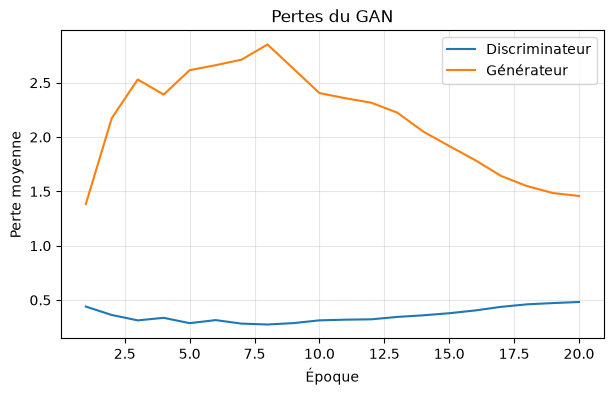

In [7]:
plt.figure(figsize=(7, 4))
plt.plot(range(1, epochs + 1), history_d, label="Discriminateur")
plt.plot(range(1, epochs + 1), history_g, label="Générateur")
plt.xlabel("Époque")
plt.ylabel("Perte moyenne")
plt.title("Pertes du GAN")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 7. Visualiser la progression

Les images enregistrées avec le même bruit fixe montrent l'évolution du générateur au fil des époques.

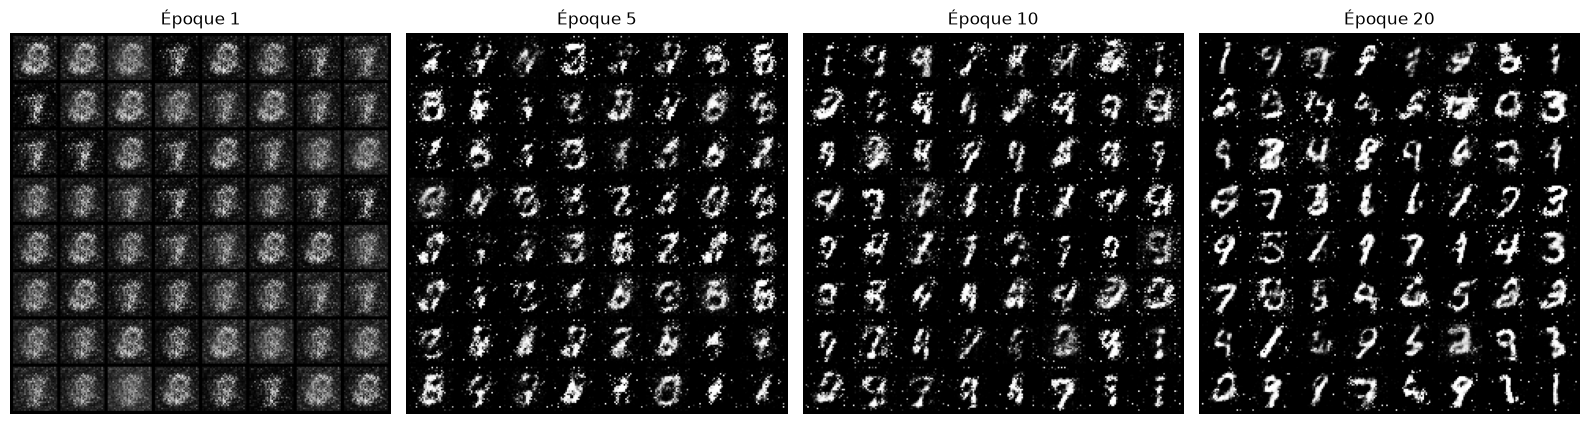

In [8]:
import matplotlib.image as mpimg

epoques = [1, 5, 10, epochs]
fig, axes = plt.subplots(1, len(epoques), figsize=(16, 4.5))
for ax, e in zip(axes, epoques):
    ax.imshow(mpimg.imread(output_dir / f"epoch_{e:03d}.png"))
    ax.set_title(f"Époque {e}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 8. Générer de nouvelles images

Après l'entraînement, le discriminateur n'est plus nécessaire : on tire de nouveaux vecteurs aléatoires
et on les donne au générateur. Ce GAN n'est pas conditionnel : on ne choisit pas quel chiffre il produit.

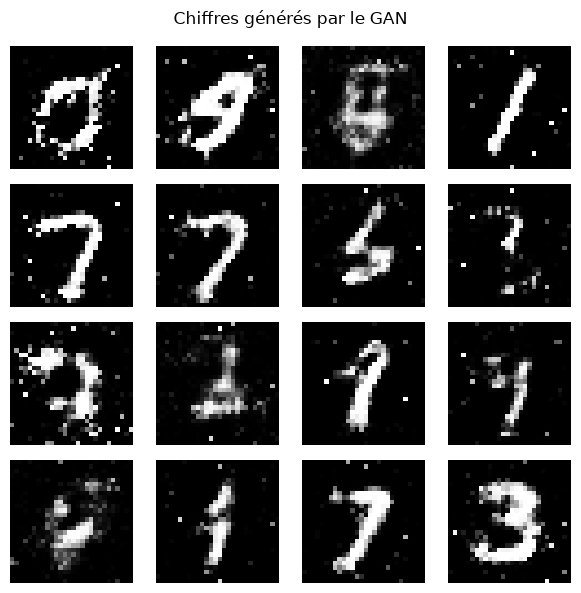

In [9]:
generator.eval()

with torch.no_grad():
    noise = torch.randn(16, latent_dim, device=device)
    images = generator(noise)

    # [16, 784] -> [16, 1, 28, 28], puis [-1, 1] -> [0, 1]
    images = images.reshape(-1, 1, 28, 28)
    images = ((images + 1) / 2).clamp(0, 1).cpu()

save_image(images, output_dir / "nouveaux_chiffres.png", nrow=4)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

fig.suptitle("Chiffres générés par le GAN")
plt.tight_layout()
plt.show()

## 9. Interpréter l'apprentissage

Les pertes d'un GAN ne diminuent pas régulièrement, car les deux réseaux poursuivent des objectifs opposés :
quand l'un progresse, la perte de l'autre augmente. Il faut donc aussi juger :

- la **qualité visuelle** des images ;
- leur **diversité** ;
- leur **évolution** au fil des époques.

Un problème possible est le **mode collapse** : le générateur ne produit que quelques types d'images, même
quand le bruit varie.